## Setup — packages, imports and dataset path

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from skimage import io, color, filters, exposure, img_as_float

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_val_score, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

DATASET_PATH = Path(r"C:\RDataFiles\archive\raw-img")
CLASS_NAMES = ["elefante", "farfalla", "gatto", "ragno"]
RANDOM_STATE = 42  # This is purely for reproducability purposes
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

assert DATASET_PATH.is_dir(), f"Dataset folder not found: {DATASET_PATH}"
for class_name in CLASS_NAMES:
    assert (DATASET_PATH / class_name).is_dir(), f"Missing class folder: {class_name}"

print("Dataset:", DATASET_PATH)
print("Classes:", CLASS_NAMES)

Dataset: C:\RDataFiles\archive\raw-img
Classes: ['elefante', 'farfalla', 'gatto', 'ragno']


## 1. Data Preparation (1 point)

### 1(a)–(b) — Use all four classes, create 36-dimensional edge histograms, and report counts

In [3]:
# This was stolen from assignment 1
def angle(dx, dy):
    """Calculate the angles between horizontal and vertical operators."""
    return np.mod(np.arctan2(dy, dx), np.pi)


def image_to_grayscale(image):
    """Grayscale conversion as in Assignment 1; handle grayscale and RGBA files too."""
    if image.ndim == 2:
        return img_as_float(image)
    if image.ndim == 3 and image.shape[2] == 3:
        return color.rgb2gray(image)
    if image.ndim == 3 and image.shape[2] == 4:
        return color.rgb2gray(color.rgba2rgb(image))
    raise ValueError(f"Unsupported image shape: {image.shape}")


def edge_histogram(image_path):
    image = io.imread(str(image_path))
    I = image_to_grayscale(image)

    # also from assignment 1
    angle_sobel = angle(filters.sobel_h(I),
                        filters.sobel_v(I))

    # believe it or not, from assignment 1
    counts, bin_centers = exposure.histogram(angle_sobel, nbins=36)
    if len(counts) != 36:
        raise ValueError(f"Expected 36 histogram bins; got {len(counts)}: {image_path}")
    return counts


X_list = []
y_list = []
image_paths = []

for class_name in CLASS_NAMES:
    class_dir = DATASET_PATH / class_name
    files = sorted(path for path in class_dir.iterdir()
                   if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS)
    if not files:
        raise ValueError(f"No image files found in {class_dir}")

    for path in files:
        X_list.append(edge_histogram(path))
        y_list.append(class_name)
        image_paths.append(path)

X = np.asarray(X_list, dtype=float)
y = np.asarray(y_list)
image_paths = np.asarray(image_paths, dtype=object)

assert X.ndim == 2 and X.shape[1] == 36
assert len(y) == len(image_paths) == len(X)

class_counts = pd.Series(y).value_counts().reindex(CLASS_NAMES)
print(f"Number of images: {len(X)}")
print(f"Number of classes: {len(CLASS_NAMES)}")
print(f"Feature vector dimensionality: {X.shape[1]}")
display(class_counts.rename_axis("Class").reset_index(name="Images"))
print("First edge-histogram vector (36 bins):")
print(X[0])

Number of images: 10047
Number of classes: 4
Feature vector dimensionality: 36


,Class,Images
0,elefante,1446
1,farfalla,2112
2,gatto,1668
3,ragno,4821


First edge-histogram vector (36 bins):
[26548.  7483.  7279.  8085.  6016.  7323.  6677.  5931.  6959.  9213.
  5922.  6385.  6883.  5585.  7204.  6020.  6018.  6640.  8959.  6214.
  6434.  7399.  5725.  7484.  6775.  5968.  6864. 10137.  6102.  6929.
  7845.  6363.  8592.  7690.  7875.  7114.]


### 1(c) — Stratified 80/20 training/test split

In [4]:
# Split the data
X_train, X_test, y_train, y_test, paths_train, paths_test = train_test_split(
    X, y, image_paths, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

split_counts = pd.DataFrame({
    "Full dataset": pd.Series(y).value_counts(),
    "Training": pd.Series(y_train).value_counts(),
    "Test": pd.Series(y_test).value_counts()
}).reindex(CLASS_NAMES).fillna(0).astype(int)

print(f"Training set: {len(X_train)} images ({len(X_train) / len(X):.1%})")
print(f"Test set:     {len(X_test)} images ({len(X_test) / len(X):.1%})")
display(split_counts)
print("Training proportions:")
display((split_counts["Training"] / len(X_train)).round(3))
print("Test proportions:")
display((split_counts["Test"] / len(X_test)).round(3))

Training set: 8037 images (80.0%)
Test set:     2010 images (20.0%)


,Full dataset,Training,Test
elefante,1446,1157,289
farfalla,2112,1689,423
gatto,1668,1334,334
ragno,4821,3857,964


Training proportions:


elefante    0.144
farfalla    0.210
gatto       0.166
ragno       0.480
Name: Training, dtype: float64

Test proportions:


elefante    0.144
farfalla    0.210
gatto       0.166
ragno       0.480
Name: Test, dtype: float64

### 1(d) — Fit standardization on training data only

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

print("Training shape:", X_train_scaled.shape)
print("First five learned training means:", np.round(scaler.mean_[:5], 3))
print("First five learned training variances:", np.round(scaler.var_[:5], 3))
print("First five standardized feature means:", np.round(X_train_scaled.mean(axis=0)[:5], 6))

Training shape: (8037, 36)
First five learned training means: [22299.431  4174.845  4085.764  4448.221  3770.892]
First five learned training variances: [7.58361408e+10 6.00821957e+08 6.02110719e+08 7.97721708e+08
 5.12463662e+08]
First five standardized feature means: [-0. -0.  0.  0. -0.]


### 1(e) — Transform test data using training means/variances only

In [6]:
X_test_scaled = scaler.transform(X_test)  # Important: do NOT use fit() or fit_transform() here.
print("Test shape:", X_test_scaled.shape)
print("Training and test feature dimensions:", X_train_scaled.shape[1], X_test_scaled.shape[1])

Test shape: (2010, 36)
Training and test feature dimensions: 36 36


Section 1(e): Why not fit the scaler using all images?

> The parameters can only be learned from the training data precisely because we don't want to learn from the test set as well. We want to leave the model unaware of the test set data so that we can see how well it generalizes to it. By using all images, we would let the model train on the test set, which would then produce more "optimistic" results of how the model behaves as opposed to just training it on the training set and not the test set.

## 2. Performance Comparison (4 points)

### 2(a) — Stratified 5-fold cross-validation for the assigned classifiers

In [7]:
# The last 4 digits of my rowan ID are 3475, which is a decision tree, neural network and adaboost
classifiers = {
    "Decision Tree": DecisionTreeClassifier(max_depth=10),
    "Neural Network": MLPClassifier(hidden_layer_sizes=(10, 10, 10)),
    "AdaBoost": AdaBoostClassifier()
}

cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, model in classifiers.items():
    # Fold-specific preprocessing prevents CV leakage from the fold's validation data.
    pipeline = make_pipeline(StandardScaler(), model)
    scores = cross_val_score(pipeline, X_train, y_train, cv=cv_stratified,
                             scoring="accuracy")
    cv_rows.append({
        "Classifier": name,
        "Mean validation accuracy": scores.mean(),
        "Standard deviation": scores.std(),
        "Fold accuracies": np.round(scores, 4).tolist()
    })

cv_results = pd.DataFrame(cv_rows).set_index("Classifier")
display(cv_results.style.format({
    "Mean validation accuracy": "{:.4f}", "Standard deviation": "{:.4f}"
}))

C:\Users\allan\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\allan\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\allan\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\allan\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\allan\anaconda3\Lib\site-packages\sklearn\neural_network\_multi

,Mean validation accuracy,Standard deviation,Fold accuracies
Classifier,,,
Decision Tree,0.5011,0.0097,"[0.4832, 0.5019, 0.5059, 0.5121, 0.5022]"
Neural Network,0.5701,0.0128,"[0.5553, 0.5784, 0.5899, 0.5582, 0.5688]"
AdaBoost,0.4974,0.0032,"[0.4944, 0.5006, 0.4935, 0.5016, 0.4972]"


### 2(b) — Choose a classifier using **only** cross-validation

In [8]:
# Avoiding the use of test results (as 1e explained why)
cv_ranked = cv_results.sort_values(
    by=["Mean validation accuracy", "Standard deviation"],
    ascending=[False, True]
)
print("Cross-validation ranking (highest mean, then lower SD as a tiebreak):")
display(cv_ranked[["Mean validation accuracy", "Standard deviation"]])
print("Tentative CV-only choice:", cv_ranked.index[0])

Cross-validation ranking (highest mean, then lower SD as a tiebreak):


,Mean validation accuracy,Standard deviation
Classifier,,
Neural Network,0.570114,0.012825
Decision Tree,0.501060,0.009662
AdaBoost,0.497449,0.003229


Tentative CV-only choice: Neural Network


Section 2(b): 

> I'd select the neural network due to the fact that it has a mean validation accuracy of .5701 and a standard deviation of .0128. The decision tree had a mean validation accuracy of .5011 and standard deviation of .0097. The AdaBoost model had a mean validation accuracy of .4974 and standard deviation of .0032. It is important to mention that the increased variability in the neural network can be very concerning, but I would argue that the difference between accuracy between the neural network and the next best (decision tree) is .07, while the standard deviation is .003 greater. While we might sacrifice some possible error, the amount of accuracy gained is much more valuable.

### 2(c) — Train each on the entire training set; test accuracy, macro-F1 and confusion matrices

C:\Users\allan\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


,Test accuracy,Macro F1-score
Classifier,,
Decision Tree,0.5199,0.4346
Neural Network,0.5920,0.4539
AdaBoost,0.5040,0.2838


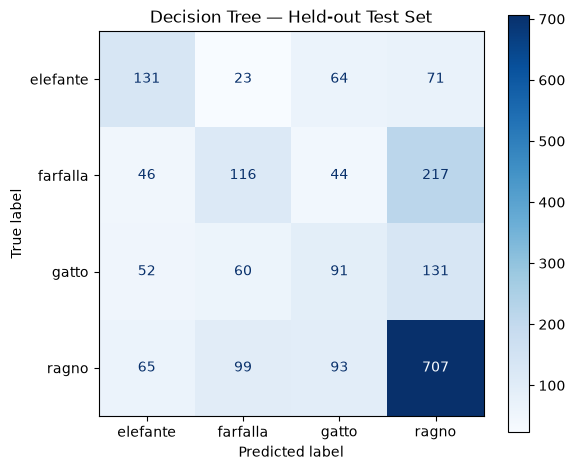

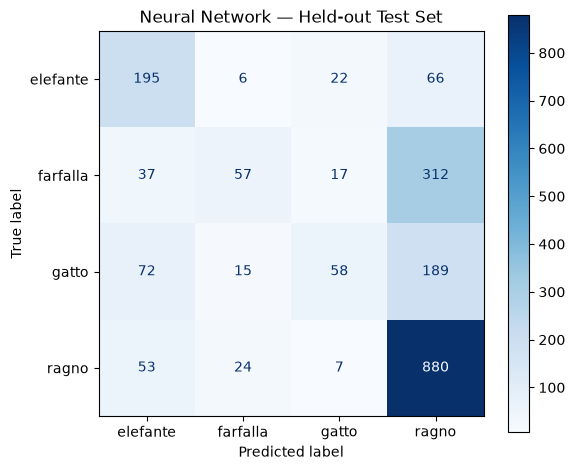

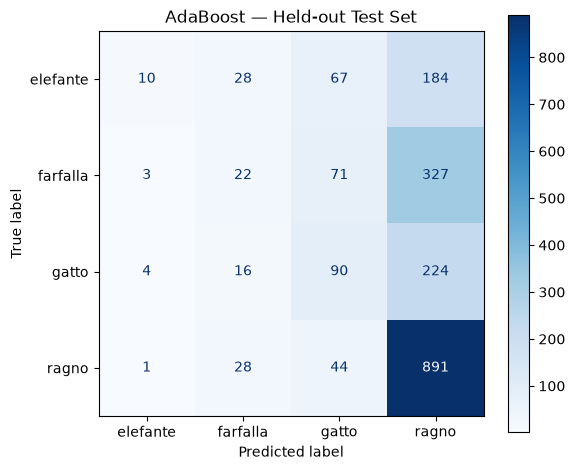

In [9]:
# Importantly, this is ran after cross-validaiton has been performed
fitted_models = {}
test_predictions = {}
confusion_matrices = {}
test_rows = []

for name, model in classifiers.items():
    model.fit(X_train_scaled, y_train)  # Use Section 1 training-only scaler.
    y_pred = model.predict(X_test_scaled)

    fitted_models[name] = model
    test_predictions[name] = y_pred
    confusion_matrices[name] = confusion_matrix(y_test, y_pred, labels=CLASS_NAMES)
    test_rows.append({
        "Classifier": name,
        "Test accuracy": accuracy_score(y_test, y_pred),
        "Macro F1-score": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

test_results = pd.DataFrame(test_rows).set_index("Classifier")
display(test_results.style.format("{:.4f}"))

for name, predictions in test_predictions.items():
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=CLASS_NAMES,
        display_labels=CLASS_NAMES, ax=ax, cmap="Blues", values_format="d"
    )
    ax.set_title(f"{name} — Held-out Test Set")
    plt.tight_layout()
    plt.show()

### 2(d) — Identify the pair of classes most frequently confused

In [10]:
# Simply, sum all the confused cases together regardless of type.
confused_rows = []
for i in range(len(CLASS_NAMES)):
    for j in range(i + 1, len(CLASS_NAMES)):
        a, b = CLASS_NAMES[i], CLASS_NAMES[j]
        row = {"Class A": a, "Class B": b}
        for name, cm in confusion_matrices.items():
            row[name] = int(cm[i, j] + cm[j, i])
        row["Total across models"] = sum(row[name] for name in classifiers)
        confused_rows.append(row)

confused_pairs = pd.DataFrame(confused_rows).sort_values(
    "Total across models", ascending=False
).reset_index(drop=True)
display(confused_pairs)

most_confused_pair = tuple(confused_pairs.loc[0, ["Class A", "Class B"]])
if confused_pairs.loc[0, "Total across models"] == 0:
    print("No test-set confusion between ANY pair across these models.")
else:
    print("Most frequently confused pair:", most_confused_pair)
    print("Number of mistakes (sum across three models):",
          int(confused_pairs.loc[0, "Total across models"]))

,Class A,Class B,Decision Tree,Neural Network,AdaBoost,Total across models
0,farfalla,ragno,316,336,355,1007
1,gatto,ragno,224,196,268,688
2,elefante,ragno,136,119,185,440
3,elefante,gatto,116,94,71,281
4,farfalla,gatto,104,32,87,223
5,elefante,farfalla,69,43,31,143


Most frequently confused pair: ('farfalla', 'ragno')
Number of mistakes (sum across three models): 1007


Section 2(d): 

>  It appears that farfalla and ragno were the most confused pair. As about 1007 combined off-diagonal errors were present across all three models used. These classes are butterflies and spiders, respectively. While to the human eye, they are different, to the model, it seems likely that the distribution of edges between butterfly wings and spider legs could be similar, and confusing the model. The 36 dimensional edge histograms measure the given frequency of edge orientations without care for their spatial locations, hence the model may be confused despite the fact that it may seem obvious to us the difference between a butterfly and spider.

### 2(e) — Display two misclassified images from the identified pair

Classifier used for examples: AdaBoost
Available mistakes between this pair: 355
File: OIP-Vd1jwbU946QJqeeIMlAD0QHaFC.jpeg | True: farfalla | Predicted: ragno
File: OIP-yNGnUjnZ7cuskPMqHg50JwHaFB.jpeg | True: ragno | Predicted: farfalla


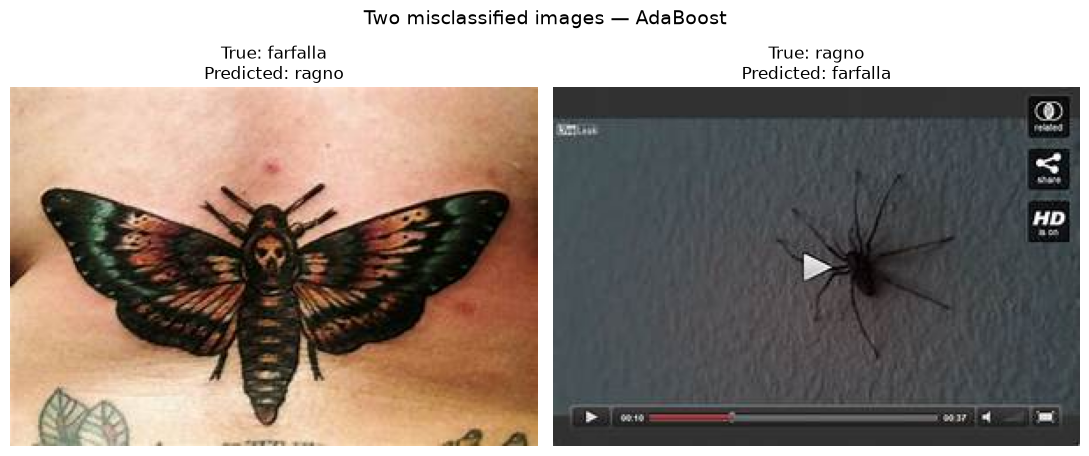

In [11]:
# Simply, find two confused images from the confused pairs (spiders and butterflies)
a, b = most_confused_pair
pair_mistakes = {}
for name, preds in test_predictions.items():
    indices = np.flatnonzero(
        np.isin(y_test, [a, b]) & np.isin(preds, [a, b]) & (y_test != preds)
    )
    pair_mistakes[name] = indices

selected_name = max(pair_mistakes, key=lambda n: len(pair_mistakes[n]))
selected_indices = pair_mistakes[selected_name]
print("Classifier used for examples:", selected_name)
print("Available mistakes between this pair:", len(selected_indices))

if len(selected_indices) < 2:
    print("Fewer than two available misclassifications in this pair for this classifier.")
    print("Cannot honestly show two; review a different classifier or pair if permitted.")
else:
    # Prefer one mistake from each direction when both directions exist.
    first = selected_indices[0]
    reverse = [i for i in selected_indices if y_test[i] != y_test[first]]
    second = reverse[0] if reverse else selected_indices[1]
    examples = [first, second]

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for ax, i in zip(axes, examples):
        img = io.imread(str(paths_test[i]))
        ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
        ax.set_title(f"True: {y_test[i]}\nPredicted: {test_predictions[selected_name][i]}")
        ax.axis("off")
        print(f"File: {paths_test[i].name} | True: {y_test[i]} "
              f"| Predicted: {test_predictions[selected_name][i]}")
    fig.suptitle(f"Two misclassified images — {selected_name}", fontsize=14)
    plt.tight_layout()
    plt.show()

Section 2(e): 

> Image 1 is truly farfalla (a butterfly) but is predicted as ragno (a spider). Visually, this is because the edges of the butterfly (specifically on the limbs attached to the face and the legs) can easily be mistaken for spider legs. Additionally, the butterfly torso (the part that is not the wings) looks very similar to the torso of a spider, so the edges might seem like that of spider to the model.
>
> Image 2 is truly ragno (a spider) but is predicted as farfalla (a butterfly). This case seems much harder to determine, however the torsos once again can realistically produce edge histograms that look very similar, which can be confusing. However, I'm struggling to see how the model saw any resemblance of the edge histograms that are for wings in this picture.

## 3. Model Selection and Model Complexity (3.5 points)

### Section 3 setup — State two potentially difficult classes

In [12]:
# Farfalla and ragno were obviously difficult for the model not to confuse (as you might have seen earlier)
SVM_CLASSES = ("farfalla", "ragno")
assert len(SVM_CLASSES) == 2 and len(set(SVM_CLASSES)) == 2
assert set(SVM_CLASSES).issubset(CLASS_NAMES)

# Not creating a new split, just subsetting
mask_train_2 = np.isin(y_train, SVM_CLASSES)
mask_test_2 = np.isin(y_test, SVM_CLASSES)
X_train_2, y_train_2 = X_train[mask_train_2], y_train[mask_train_2]
X_test_2, y_test_2 = X_test[mask_test_2], y_test[mask_test_2]

print("Two classes selected:", SVM_CLASSES)
print("Training counts:", pd.Series(y_train_2).value_counts().to_dict())
print("Test counts:", pd.Series(y_test_2).value_counts().to_dict())
assert pd.Series(y_train_2).value_counts().min() >= 5, "Need at least 5 training images per selected class."

Two classes selected: ('farfalla', 'ragno')
Training counts: {'ragno': 3857, 'farfalla': 1689}
Test counts: {'ragno': 964, 'farfalla': 423}


Section 3 (class choice): 

> I will select farfalla and ragno - as tested before, the models had a tendency to confuse them. Thus they are great "difficult" classes to test.

### 3(a) — Standard vs. stratified 5-fold CV; four mean-error curves for six C values

,C,CV approach,Mean training error (%),Mean validation error (%)
0,0.01,Standard,27.62,27.89
1,0.01,Stratified,27.63,27.88
2,0.1,Standard,27.58,27.91
3,0.1,Stratified,27.53,28.04
4,1,Standard,27.61,27.93
5,1,Stratified,27.56,28.27
6,10,Standard,27.59,27.93
7,10,Stratified,27.55,28.16
8,100,Standard,27.59,27.89
9,100,Stratified,27.55,28.18


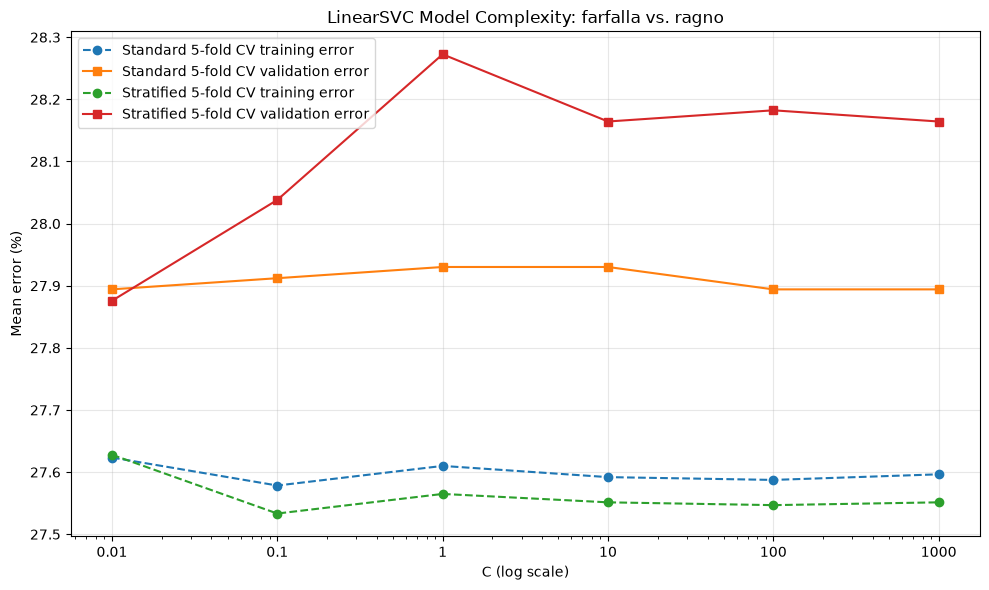

In [13]:
C_VALUES = [0.01, 0.1, 1, 10, 100, 1000]

# The random_state stated earlier is so it can be reproduced.
standard_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True,
                               random_state=RANDOM_STATE)

svm_rows = []
for c in C_VALUES:
    for cv_name, cv in [("Standard", standard_cv), ("Stratified", stratified_cv)]:
        pipeline = make_pipeline(StandardScaler(), LinearSVC(C=c))
        scores = cross_validate(
            pipeline, X_train_2, y_train_2,
            cv=cv, scoring="accuracy", return_train_score=True
        )
        svm_rows.append({
            "C": c,
            "CV approach": cv_name,
            "Mean training error (%)": 100 * (1 - scores["train_score"].mean()),
            "Mean validation error (%)": 100 * (1 - scores["test_score"].mean())
        })

svm_results = pd.DataFrame(svm_rows)
display(svm_results.style.format({
    "C": "{:g}",
    "Mean training error (%)": "{:.2f}",
    "Mean validation error (%)": "{:.2f}"
}))

plt.figure(figsize=(10, 6))
for cv_name in ("Standard", "Stratified"):
    subset = svm_results[svm_results["CV approach"] == cv_name]
    plt.plot(subset["C"], subset["Mean training error (%)"],
             marker="o", linestyle="--", label=f"{cv_name} 5-fold CV training error")
    plt.plot(subset["C"], subset["Mean validation error (%)"],
             marker="s", linestyle="-", label=f"{cv_name} 5-fold CV validation error")

plt.xscale("log")
plt.xticks(C_VALUES, [str(v) for v in C_VALUES])
plt.xlabel("C (log scale)")
plt.ylabel("Mean error (%)")
plt.title(f"LinearSVC Model Complexity: {SVM_CLASSES[0]} vs. {SVM_CLASSES[1]}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3(b) — Best C, underfitting/overfitting, and distribution of classes in folds

In [14]:
minima = svm_results.loc[
    svm_results.groupby("CV approach")["Mean validation error (%)"].idxmin(),
    ["CV approach", "C", "Mean training error (%)", "Mean validation error (%)"]
].sort_values("CV approach")
print("C with the lowest mean validation error for each CV approach:")
display(minima)

for cv_name, cv in [("Standard", standard_cv), ("Stratified", stratified_cv)]:
    rows = []
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_2, y_train_2), start=1):
        train_counts = pd.Series(y_train_2[train_idx]).value_counts()
        val_counts = pd.Series(y_train_2[val_idx]).value_counts()
        row = {"Fold": fold}
        for label in SVM_CLASSES:
            row[f"Train: {label}"] = int(train_counts.get(label, 0))
            row[f"Validation: {label}"] = int(val_counts.get(label, 0))
        rows.append(row)
    print(f"{cv_name} 5-fold CV — class counts in each fold:")
    display(pd.DataFrame(rows).set_index("Fold"))

C with the lowest mean validation error for each CV approach:


,CV approach,C,Mean training error (%),Mean validation error (%)
8,Standard,100.00,27.587459,27.894150
1,Stratified,0.01,27.628010,27.875807


Standard 5-fold CV — class counts in each fold:


,Train: farfalla,Validation: farfalla,Train: ragno,Validation: ragno
Fold,,,,
1,1358,331,3078,779
2,1333,356,3104,753
3,1364,325,3073,784
4,1364,325,3073,784
5,1337,352,3100,757


Stratified 5-fold CV — class counts in each fold:


,Train: farfalla,Validation: farfalla,Train: ragno,Validation: ragno
Fold,,,,
1,1351,338,3085,772
2,1352,337,3085,772
3,1351,338,3086,771
4,1351,338,3086,771
5,1351,338,3086,771


Section 3(b):

1. Lowest Mean Validation Error is Standard 5-fold Cross Validation with C = 100 - Mean validaiton error is 27.894%. Stratified 5-fold Cross Validation with C = 0.01, with a mean validation error of 27.876%
2. How does increasing C affect model complexity? By increasing C, we thereby reduce regularization. Our SVM will then become much more sensitive to training errors - which means we will fit the training data more, which allows a dangerous possibility of overfitting. A smaller C means stronger regularization, which is akin to making the model quite simpler.
3. Is there evidence of underfitting? There does appear to be evidence of underfitting given that at C = 0.01, our stratified cross validation training error is 27.628% and our validation error is 27.876%. These are quite high errors, an indicator that the model had quite the rough time differentiating between spiders and butterflies. But this is not necessarily an indicator of underfitting, as C = 0.01 produced the lowest stratified validation error.
4. Is there evidence of overfitting? Overfitting seems unlikely here. With C = 100, the standard cross validation training error was 27.586% and a validation eror of 27.894%. The difference is roughly .31%, which is not a considerable difference. A larger difference would be indicative of overfitting, but this difference is not very large, hence there does not seem to be evidence that the model overfit.
5. Are standard and stratified cross-validation similar? By the results, yes they are quite similar. Standard cross validaition achieved a minimum validation error of 27.8942%, while stratified cross validation achieved 27.8758%, a difference of approximately 0.0183%. This makes sense as the class distributions were quite similar - for standard cross validation about 325-356 butterfly photos were used and 753-784 spider photoes in validation sets. Stratified cross validation was similar with 337-338 butterfly images and 771-772 spider images. While the values aren't identical, they are quite similar, so the reuslts are not surprising.

## 3(c) — Train on all two-class training data using best stratified C; test error

In [15]:
stratified_rows = svm_results[svm_results["CV approach"] == "Stratified"]

best_row = stratified_rows.loc[stratified_rows["Mean validation error (%)"].idxmin()]
best_C = float(best_row["C"])
best_cv_error = float(best_row["Mean validation error (%)"])


scaler_2 = StandardScaler()
X_train_2_scaled = scaler_2.fit_transform(X_train_2)
X_test_2_scaled = scaler_2.transform(X_test_2)

best_svm = LinearSVC(C=best_C)  # Every other LinearSVC parameter is default.
best_svm.fit(X_train_2_scaled, y_train_2)
svm_test_predictions = best_svm.predict(X_test_2_scaled)
svm_test_error = 100 * (1 - accuracy_score(y_test_2, svm_test_predictions))

print(f"Best C from stratified CV: {best_C:g}")
print(f"Mean stratified CV validation error: {best_cv_error:.2f}%")
print(f"Held-out two-class test error: {svm_test_error:.2f}%")
print(f"Absolute error difference: {abs(svm_test_error - best_cv_error):.2f} percentage points")

Best C from stratified CV: 0.01
Mean stratified CV validation error: 27.88%
Held-out two-class test error: 27.69%
Absolute error difference: 0.19 percentage points


Section 3(c):

> The best value for C was 0.01 for stratified 5 fold cross validation. The mean validation error was 27.88%. The held-out test error for the LinearSVC was 27.69%. The difference between these two is about .19%, which is not much. This is an indicator that the model generalizes pretty well and did not overfit.

## 4. Final Analysis — What Did You Learn? (1.5 points)

In [16]:
summary = cv_results[["Mean validation accuracy", "Standard deviation"]].join(test_results)
print("Summary of Section 2 for your final response:")
display(summary.style.format("{:.4f}"))
print("Most confused class pair under the declared Section 2(d) counting rule:", most_confused_pair)

Summary of Section 2 for your final response:


,Mean validation accuracy,Standard deviation,Test accuracy,Macro F1-score
Classifier,,,,
Decision Tree,0.5011,0.0097,0.5199,0.4346
Neural Network,0.5701,0.0128,0.5920,0.4539
AdaBoost,0.4974,0.0032,0.5040,0.2838


Most confused class pair under the declared Section 2(d) counting rule: ('farfalla', 'ragno')


Section 4 (150 words or fewer):
> The neural network appears to be ther clear best classifier. It had the highest cross-validation accuracy (57.01%), the highest test accuracy (59.20%) and highest macro-f1 score (.4539). While one might point to its standard deviation being larger than the others (.0128), its a worthy sacrifice for just how much more accurate it is. The decision tree performed admirably, while AdaBoost was quite poor. According to the confusion matrices, spiders (ragno) and butterflies (farfalla) were the most confused classes due to the fact that their complex outlines (on wings and legs specifically) have similar edge orientations. I would recommend using Histogram of Oriented Gradients, as it retains spatial informaiton on edges, which would greatly help in differentiating between spiders and butterflies.

## Sources and implementation notes
- scikit-learn User Guide: https://scikit-learn.org/stable/user_guide.html
- DecisionTreeClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
- MLPClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html
- AdaBoostClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html
- train_test_split: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
- StratifiedKFold: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html
- KFold: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html
- cross_val_score: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html
- cross_validate: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html
- Pipeline / make_pipeline: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html
- StandardScaler: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
- LinearSVC: https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html
- ConfusionMatrixDisplay: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html
- `skimage.exposure.histogram`: https://scikit-image.org/docs/stable/api/skimage.exposure.html#skimage.exposure.histogram
- `skimage.filters.sobel_h / sobel_v`: https://scikit-image.org/docs/stable/api/skimage.filters.html
- `skimage.color.rgb2gray`: https://scikit-image.org/docs/stable/api/skimage.color.html#skimage.color.rgb2gray